In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
# Configuration
np.random.seed(42)
n_samples = 100

# Here, we will try to generate synthetic linear data
X = np.linspace(0, 10, n_samples).reshape(-1, 1)
y = 2 * X.ravel() + 1 + np.random.randn(n_samples) * 2

In [6]:
X[:10]

array([[0.        ],
       [0.1010101 ],
       [0.2020202 ],
       [0.3030303 ],
       [0.4040404 ],
       [0.50505051],
       [0.60606061],
       [0.70707071],
       [0.80808081],
       [0.90909091]])

In [8]:
y[:10]

array([1.99342831, 0.9254916 , 2.69941748, 4.65212032, 1.33977406,
       1.5418271 , 5.37054684, 3.94901087, 1.67721284, 3.90330191])

**Data Generation**

In [ ]:
# Configuration
np.random.seed(42)
n_samples = 100

# Here, we will try to generate synthetic linear data.
X = np.linspace(0, 10, n_samples).reshape(-1, 1)
y = 2 * X.ravel() + 1 + np.random.randn(n_samples) * 2

In [11]:
X[:10]

array([[0.        ],
       [0.1010101 ],
       [0.2020202 ],
       [0.3030303 ],
       [0.4040404 ],
       [0.50505051],
       [0.60606061],
       [0.70707071],
       [0.80808081],
       [0.90909091]])

In [12]:
y[:10]

array([1.99342831, 0.9254916 , 2.69941748, 4.65212032, 1.33977406,
       1.5418271 , 5.37054684, 3.94901087, 1.67721284, 3.90330191])

**Data Splitting**


In [14]:
# Split data: 70% Train, 30% Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

**Model Training & Validation**

## Basic Training 

In [ ]:
# Model Initialization
model = LinearRegression()

# We will start with a simple training process first
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Calculate the evaluation metrics
mse_holdout = mean_squared_error(y_test, y_pred)
r2_holdout = r2_score(y_test, y_pred)

print(f"--- Hold-out Evaluation (30% Test) ---")
print(f"Test MSE: {mse_holdout:.2f}")
print(f"Test R2:  {r2_holdout:.2f}\n")

--- Hold-out Evaluation (30% Test) ---
Test MSE: 2.22
Test R2:  0.94



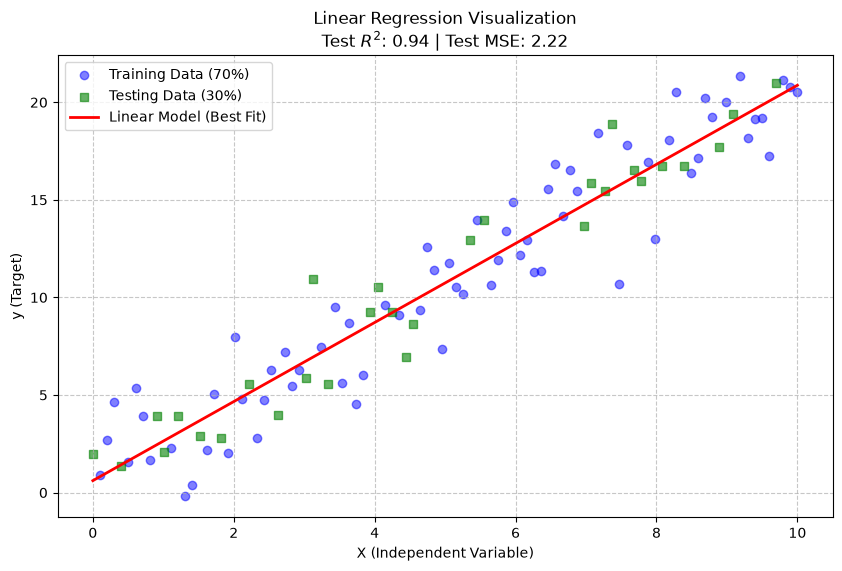

In [ ]:
# Create a range covering all the data points
X_range = np.linspace(0, 10, 100).reshape(-1, 1)
y_range_pred = model.predict(X_range)

plt.figure(figsize=(10, 6))

# Plot Training Data
plt.scatter(X_train, y_train, color='blue', alpha=0.5, label='Training Data (70%)')

# Plot Testing Data
plt.scatter(X_test, y_test, color='green', alpha=0.6, label='Testing Data (30%)', marker='s')

# Plot Regression linenya
plt.plot(X_range, y_range_pred, color='red', linewidth=2, label='Linear Model (Best Fit)')

# Showing
plt.title(f"Linear Regression Visualization\nTest $R^2$: {r2_holdout:.2f} | Test MSE: {mse_holdout:.2f}")
plt.xlabel("X (Independent Variable)")
plt.ylabel("y (Target)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

**K-fold Cross Validation**

Cross-Validation (CV) is a more robust evaluation technique. Instead of splitting the data just once, we divide it into $K$ parts (called folds).

**How K-Fold Works (For Example, K = 5):**

1. The data is divided into 5 equal parts.
2. Iteration 1: Part 1 is used as the test data, while the remaining parts (2, 3, 4, 5) are used as training data.
3. Iteration 2: Part 2 is used as the test data, while the remaining parts are used as training data.
4. This process is repeated until every part has been used as test data once.
5. The final result is the average of the scores from each iteration.

In [19]:
# 5-Fold Cross Validation
# We will use the entire dataset (X, y) because cross_val_score
# will handle the data splitting automatically.
model = LinearRegression()
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_r2_scores = cross_val_score(model, X, y, cv=kf, scoring='r2')
cv_mse_scores = -cross_val_score(model, X, y, cv=kf, scoring='neg_mean_squared_error')

print(f"--- 5-Fold Cross-Validation ---")
print(f"Mean CV R2:   {cv_r2_scores.mean():.4f} ± {cv_r2_scores.std():.4f}")
print(f"Mean CV MSE:  {cv_mse_scores.mean():.2f} ± {cv_mse_scores.std():.2f}")

--- 5-Fold Cross-Validation ---
Mean CV R2:   0.9018 ± 0.0325
Mean CV MSE:  3.32 ± 1.43


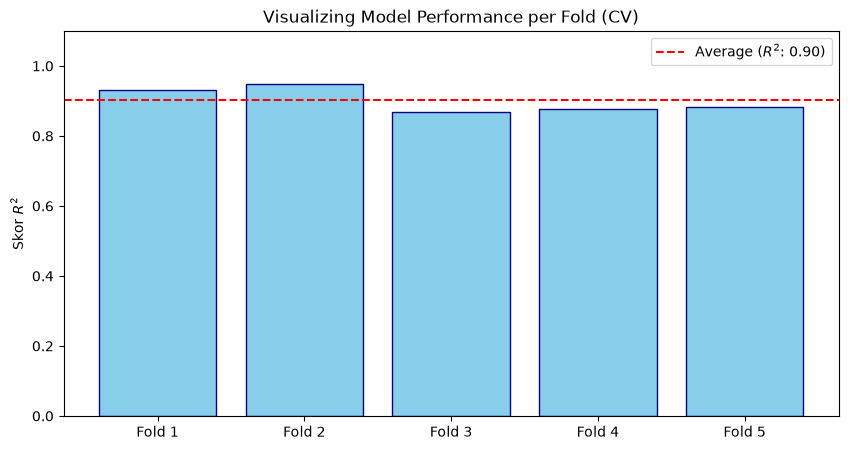

In [22]:
# Visualizing the Cross-Validation Results
plt.figure(figsize=(10, 5))
folds = [f"Fold {i+1}" for i in range(len(cv_r2_scores))]
plt.bar(folds, cv_r2_scores, color='skyblue', edgecolor='navy')
plt.axhline(y=cv_r2_scores.mean(), color='red', linestyle='--', label=f'Average ($R^2$: {cv_r2_scores.mean():.2f})')

plt.title("Visualizing Model Performance per Fold (CV)")
plt.ylabel("Skor $R^2$")
plt.ylim(0, 1.1)
plt.legend()
plt.show()